## Inicialization

In [ ]:
# importing required libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import RepeatedKFold

#### Functions created for this project

In [3]:
def transformar_sexo(valor):

    '''Converting categorical variables to numerical variables'''

    if valor =='female':
        return 1
    else:
        return 0

## Loading the data

In [4]:
# loading the data files into different DataFrames
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

## Initial Assesssment

### Train dataset

In [5]:
# inspect dataset structure
#df_train.info()

In [6]:
# inspect a sample of records
#print(df_train.sample(5))

**Initial datasets assessment**



In [7]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
train['Sex_binario'] = train['Sex'].map(transformar_sexo)
test['Sex_binario'] = test['Sex'].map(transformar_sexo)

In [ ]:
variaveis = ['Sex_binario', 'Age']

### Definig features and target variable

In [ ]:
X = train[variaveis]
y = train['Survived']

In [11]:
print(train.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  Sex_binario  
0      0         A/5 21171   7.2500   NaN        S            0  
1      0          PC 17599  71.2833   C85        C            1  
2      0  STON/O2. 3101282   7.9250   NaN        S            1  
3      0            113803  53.1000  C123        S      

### Splitting the dataset

In [14]:
np.random.seed(0)
X_treino, X_valid, y_treino, y_valid = train_test_split(X, y, test_size=0.5)

In [15]:
X_treino.head()

,Sex_binario,Age
213,0,30.0
586,0,47.0
499,0,24.0
821,0,27.0
246,1,25.0


In [16]:
X_treino.shape, X_valid.shape, y_treino.shape, y_valid.shape

((445, 2), (446, 2), (445,), (446,))

### Creating the model

In [17]:
modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)

In [18]:
# training the model
modelo.fit(X_treino, y_treino)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

In [19]:
# making predicts
p = modelo.predict(X_valid)

In [20]:
# creating a simpler test validation
np.mean(y_valid == p).round(2)

np.float64(0.77)

### Cross Validation

In [ ]:
resultados = []
kf = RepeatedKFold(n_splits=2, n_repeats=10, random_state=10)

for linhas_treino, linhas_valid in kf.split(X):
    print('Treino', linhas_treino.shape[0])
    print('Valid', linhas_valid.shape[0])
    
    X_treino, X_valid = X.iloc[linhas_treino], X.iloc[linhas_valid]
    y_treino, y_valid = y.iloc[linhas_treino], y.iloc[linhas_valid]

    modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
    modelo.fit(X_treino, y_treino)

    p = modelo.predict(X_valid)

    acc = np.mean(y_valid == p)
    resultados.append(acc)
    print('Acc:', acc)
    print()
    #print(X_treino.head())
    #print()

Treino 445
Valid 446
Acc: 0.7511210762331838

Treino 446
Valid 445
Acc: 0.7617977528089888

Treino 445
Valid 446
Acc: 0.7533632286995515

Treino 446
Valid 445
Acc: 0.7595505617977528

Treino 445
Valid 446
Acc: 0.7690582959641256

Treino 446
Valid 445
Acc: 0.7573033707865169

Treino 445
Valid 446
Acc: 0.7399103139013453

Treino 446
Valid 445
Acc: 0.7573033707865169

Treino 445
Valid 446
Acc: 0.7354260089686099

Treino 446
Valid 445
Acc: 0.797752808988764

Treino 445
Valid 446
Acc: 0.7690582959641256

Treino 446
Valid 445
Acc: 0.7617977528089888

Treino 445
Valid 446
Acc: 0.7757847533632287

Treino 446
Valid 445
Acc: 0.7573033707865169

Treino 445
Valid 446
Acc: 0.7556053811659192

Treino 446
Valid 445
Acc: 0.7640449438202247

Treino 445
Valid 446
Acc: 0.7443946188340808

Treino 446
Valid 445
Acc: 0.7595505617977528

Treino 445
Valid 446
Acc: 0.7533632286995515

Treino 446
Valid 445
Acc: 0.7640449438202247



In [29]:
resultados

[np.float64(0.7511210762331838),
 np.float64(0.7617977528089888),
 np.float64(0.7533632286995515),
 np.float64(0.7595505617977528),
 np.float64(0.7690582959641256),
 np.float64(0.7573033707865169),
 np.float64(0.7399103139013453),
 np.float64(0.7573033707865169),
 np.float64(0.7354260089686099),
 np.float64(0.797752808988764),
 np.float64(0.7690582959641256),
 np.float64(0.7617977528089888),
 np.float64(0.7757847533632287),
 np.float64(0.7573033707865169),
 np.float64(0.7556053811659192),
 np.float64(0.7640449438202247),
 np.float64(0.7443946188340808),
 np.float64(0.7595505617977528),
 np.float64(0.7533632286995515),
 np.float64(0.7640449438202247)]

In [22]:
np.mean(resultados)

np.float64(0.7593767319997984)

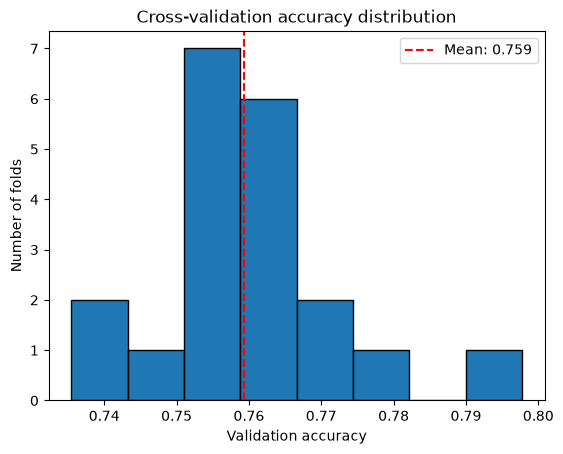

In [34]:
plt.hist(resultados, bins=8, edgecolor="black")
plt.axvline(
    np.mean(resultados),
    color="red",
    linestyle="--",
    label=f"Mean: {np.mean(resultados):.3f}",
)

plt.xlabel("Validation accuracy")
plt.ylabel("Number of folds")
plt.title("Cross-validation accuracy distribution")
plt.legend()
plt.show()

### New variables

modelo anterior = 0.759601451100922

In [36]:
print(train.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  Sex_binario  
0      0         A/5 21171   7.2500   NaN        S            0  
1      0          PC 17599  71.2833   C85        C            1  
2      0  STON/O2. 3101282   7.9250   NaN        S            1  
3      0            113803  53.1000  C123        S      

In [39]:
variaveis = ['Sex_binario', 'Age', 'Pclass', 'SibSp', 'Parch', 'Fare']

In [ ]:
X = train[variaveis].fillna(-1)
y = train['Survived']

In [41]:
resultados = []
kf = RepeatedKFold(n_splits=2, n_repeats=10, random_state=10)

for linhas_treino, linhas_valid in kf.split(X):
    print('Treino', linhas_treino.shape[0])
    print('Valid', linhas_valid.shape[0])
    
    X_treino, X_valid = X.iloc[linhas_treino], X.iloc[linhas_valid]
    y_treino, y_valid = y.iloc[linhas_treino], y.iloc[linhas_valid]

    modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
    modelo.fit(X_treino, y_treino)

    p = modelo.predict(X_valid)

    acc = np.mean(y_valid == p)
    resultados.append(acc)
    print('Acc:', acc)
    print()
    #print(X_treino.head())
    #print()

Treino 445
Valid 446
Acc: 0.7869955156950673

Treino 446
Valid 445
Acc: 0.7797752808988764

Treino 445
Valid 446
Acc: 0.827354260089686

Treino 446
Valid 445
Acc: 0.8179775280898877

Treino 445
Valid 446
Acc: 0.7847533632286996

Treino 446
Valid 445
Acc: 0.7842696629213484

Treino 445
Valid 446
Acc: 0.8161434977578476

Treino 446
Valid 445
Acc: 0.7842696629213484

Treino 445
Valid 446
Acc: 0.8004484304932735

Treino 446
Valid 445
Acc: 0.8

Treino 445
Valid 446
Acc: 0.8183856502242153

Treino 446
Valid 445
Acc: 0.802247191011236

Treino 445
Valid 446
Acc: 0.8116591928251121

Treino 446
Valid 445
Acc: 0.8067415730337079

Treino 445
Valid 446
Acc: 0.820627802690583

Treino 446
Valid 445
Acc: 0.7887640449438202

Treino 445
Valid 446
Acc: 0.8385650224215246

Treino 446
Valid 445
Acc: 0.8044943820224719

Treino 445
Valid 446
Acc: 0.7982062780269058

Treino 446
Valid 445
Acc: 0.8112359550561797



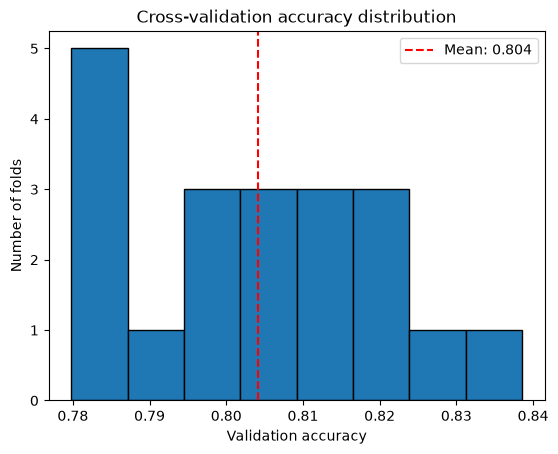

In [42]:
plt.hist(resultados, bins=8, edgecolor="black")
plt.axvline(
    np.mean(resultados),
    color="red",
    linestyle="--",
    label=f"Mean: {np.mean(resultados):.3f}",
)

plt.xlabel("Validation accuracy")
plt.ylabel("Number of folds")
plt.title("Cross-validation accuracy distribution")
plt.legend()
plt.show()

In [43]:
np.mean(resultados)

np.float64(0.8041457147175896)

### Training the model again

In [50]:
# loading the data files into different DataFrames
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
train['Sex_binario'] = train['Sex'].map(transformar_sexo)
test['Sex_binario'] = test['Sex'].map(transformar_sexo)

variaveis = ['Sex_binario', 'Age', 'Pclass', 'SibSp', 'Parch', 'Fare']
X = train[variaveis].fillna(-1)
y = train['Survived']


In [51]:
X.head()

,Sex_binario,Age,Pclass,SibSp,Parch,Fare
0,0,22.0,3,1,0,7.2500
1,1,38.0,1,1,0,71.2833
2,1,26.0,3,0,0,7.9250
3,1,35.0,1,1,0,53.1000
4,0,35.0,3,0,0,8.0500


In [52]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [53]:
test[variaveis].head()

,Sex_binario,Age,Pclass,SibSp,Parch,Fare
0,0,34.5,3,0,0,7.8292
1,1,47.0,3,1,0,7.0000
2,0,62.0,2,0,0,9.6875
3,0,27.0,3,0,0,8.6625
4,1,22.0,3,1,1,12.2875


In [54]:
modelo = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)

# Train on all labeled passengers
modelo.fit(X, y)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

### Using the test data

In [57]:
# Predict using the same features and column order
#X_test = test[variaveis]
p = modelo.predict(test[variaveis])

print('Number of predictions:', len(p))

Number of predictions: 418


### Creating a csv file to submit

In [58]:
sub = pd.Series(p, index=test['PassengerId'])
sub.shape

(418,)

In [ ]:
sub.rename('Survived').to_csv(
    '../submissions/submission_5_v.01.csv', 
    index_label='PassengerId'
)

In [ ]:
pd.read_csv('../submissions/submission_5_v.01.csv').head(10)

,PassengerId,Survived
0,892,0
1,893,0
2,894,1
3,895,1
4,896,0
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0
